In [12]:
# Imports et chargement des données
import pandas as pd
import numpy as np
import random
import tensorflow as tf
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler
import joblib
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Bidirectional, Dense, Input, Dropout, GRU
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

# Définir les graines aléatoires pour la reproductibilité
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    
data = pd.read_csv('../data/raw/AAPL.csv', index_col='Date', parse_dates=True)['Close']


data



Date
2013-01-02     16.669012
2013-01-03     16.458618
2013-01-04     16.000164
2013-01-07     15.906051
2013-01-08     15.948846
                 ...    
2022-12-23    130.344498
2022-12-27    128.535492
2022-12-28    124.591385
2022-12-29    128.120331
2022-12-30    128.436661
Name: Close, Length: 2518, dtype: float64

In [13]:
# Prétraitement des données
# Lissage exponentiel
def exponential_smoothing(data, alpha=0.5):
    smoothed_data = [data.iloc[0]]
    for i in range(1, len(data)):
        smoothed_value = alpha * data.iloc[i] + (1 - alpha) * smoothed_data[-1]
        smoothed_data.append(smoothed_value)
    return np.array(smoothed_data)

prices_smoothed = exponential_smoothing(data)

# Normalisation des données
scaler = MinMaxScaler(feature_range=(0, 1))
prices_scaled = scaler.fit_transform(prices_smoothed.reshape(-1, 1))

# Sauvegarder le scaler pour une utilisation future
joblib.dump(scaler, '../models/scaler_minmax_gru.pkl')

['scaler_minmax_gru.pkl']

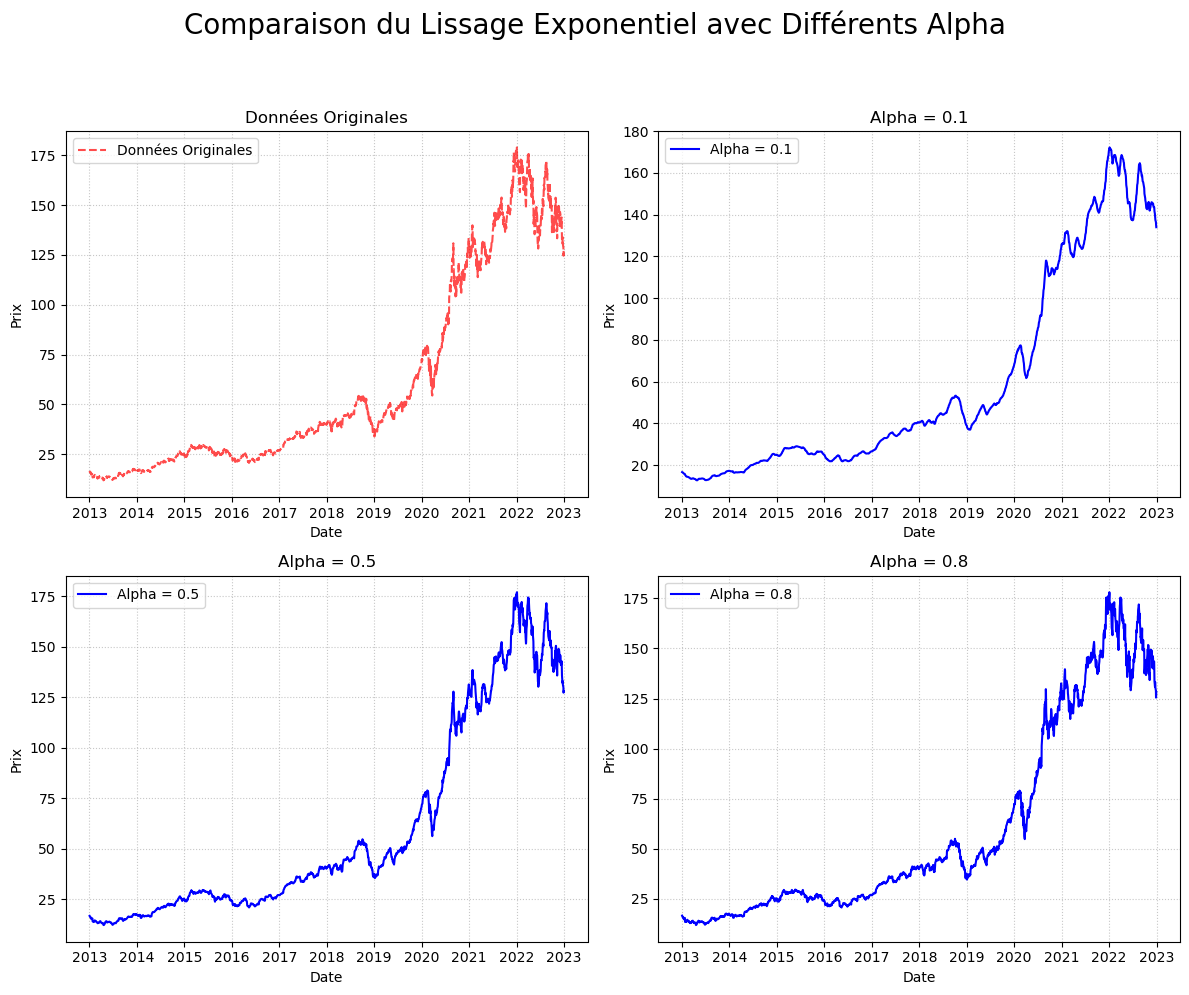

In [26]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# --- 1. Préparation des données d'exemple ---
# Remplacez ceci par le chargement de vos données réelles, par exemple :
# original_prices = pd.read_csv('votre_fichier_de_prix.csv', index_col='Date', parse_dates=True)['Close']



# --- 2. Calcul des séries de prix lissées pour chaque alpha ---
# Nous allons considérer 3 valeurs d'alpha pour le lissage + la série originale
alphas_to_plot = [0.5] # Vos alphas pour le lissage
# Nous allons inclure l'original comme 4ème courbe pour la comparaison directe

# Dictionnaire pour stocker toutes les séries à tracer
data_to_plot = {
    'Données Originales': data # La 1ère courbe : les données brutes
}

for alpha in alphas_to_plot:
    # Applique le lissage exponentiel (EWMA)
    # adjust=False pour que la moyenne mobile exponentielle démarre sans biais
    smoothed_series = exponential_smoothing(data, alpha=alpha)
    smoothed_series = pd.DataFrame(smoothed_series, index=data.index)
    data_to_plot[f'Alpha = {alpha}'] = smoothed_series

# --- 3. Création des subplots et tracé des courbes ---
# Crée une figure et un ensemble de subplots (2 lignes, 2 colonnes pour 4 graphiques)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(6, 4)) # Ajustez la taille de la figure si nécessaire
axes = axes.flatten() # Transforme la grille 2x2 en un tableau 1D pour faciliter l'itération

# Définir l'ordre des titres pour les subplots
plot_titles_order = ['Données Originales','Alpha = 0.5']

for i, title_key in enumerate(plot_titles_order):
    ax = axes[i] # Sélectionne le subplot courant
    series_to_plot = data_to_plot[title_key]

    # Définir les couleurs et styles pour chaque courbe
    if title_key == 'Données Originales':
        ax.plot(series_to_plot, label=title_key, color='red', linestyle='--', alpha=0.7)
    else:
        ax.plot(series_to_plot, label=title_key, color='blue')

    ax.set_title(f'{title_key}') # Titre du subplot
    ax.set_xlabel('Date')
    ax.set_ylabel('Prix')
    ax.legend() # Affiche la légende pour chaque subplot
    ax.grid(True, linestyle=':', alpha=0.7) # Ajoute une grille légère

# --- 4. Réglages généraux de la figure ---
# Ajoute un titre général à la figure entière
fig.suptitle('Comparaison du Lissage Exponentiel avec Différents Alpha', fontsize=20, y=1.02)

# Ajuste automatiquement les paramètres de subplot pour qu'ils s'adaptent à la zone de la figure
plt.tight_layout(rect=[0, 0.03, 1, 0.98]) # Ajuste la zone pour éviter le chevauchement du super-titre
plt.show()

In [14]:
#  Création des séquences
# Fonction pour créer les séquences

def create_sequences(data, sequence_length):
    X, y = [], []
    for i in range(len(data) - sequence_length):
        X.append(data[i:i+sequence_length])
        y.append(data[i+sequence_length])
    return np.array(X), np.array(y)

sequence_length = 3
X, y = create_sequences(prices_scaled, sequence_length)

# Diviser les données en ensembles d'entraînement et de test (70% / 30%)
train_size = int(len(X) * 0.7)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"Forme de X_train: {X_train.shape}")
print(f"Forme de y_train: {y_train.shape}")
print(f"Forme de X_test: {X_test.shape}")
print(f"Forme de y_test: {y_test.shape}")

Forme de X_train: (1760, 3, 1)
Forme de y_train: (1760, 1)
Forme de X_test: (755, 3, 1)
Forme de y_test: (755, 1)


In [15]:
#  Entraînement du modèle final
# Créer et compiler le modèle final
set_seed(42)
#  Définition du modèle

def create_model(input_shape):
    model = Sequential([
        Input(shape=input_shape),
        Bidirectional(LSTM(units=64, activation='tanh', return_sequences=True)),
        Dropout(0.25),
        Bidirectional(LSTM(units=256, activation='tanh', return_sequences=False)),
        Dropout(0.25),
        Dense(64),
        Dense(units=1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.0001), loss='huber', metrics=['mae'])
    return model
final_model = create_model(input_shape=(X_train.shape[1], X_train.shape[2]))

# Définir early stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Entraîner le modèle sur l'ensemble complet des données d'entraînement
final_history = final_model.fit(
    X_train, y_train,
    batch_size=128,
    epochs=100,
    verbose=1
)



Epoch 1/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 35s 83ms/step - loss: 0.0070 - mae: 0.0950
Epoch 2/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - loss: 0.0019 - mae: 0.0470
Epoch 3/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 0.0012 - mae: 0.0432
Epoch 4/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 8.2395e-04 - mae: 0.0349
Epoch 5/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 5.3637e-04 - mae: 0.0275
Epoch 6/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 2.6242e-04 - mae: 0.0196
Epoch 7/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - loss: 1.0200e-04 - mae: 0.0116
Epoch 8/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 3.2046e-05 - mae: 0.0061
Epoch 9/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 2.7689e-05 - mae: 0.0050
Epoch 10/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 2.7272e-05 - mae: 0.0051
Epoch 11/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 2.8700e-05 - mae: 0.0051
Epoch 12/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 2.8222e-05 - 

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 7.6433e-05 - mae: 0.0091
Test Loss: 0.0001, Test MAE: 0.0110
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step


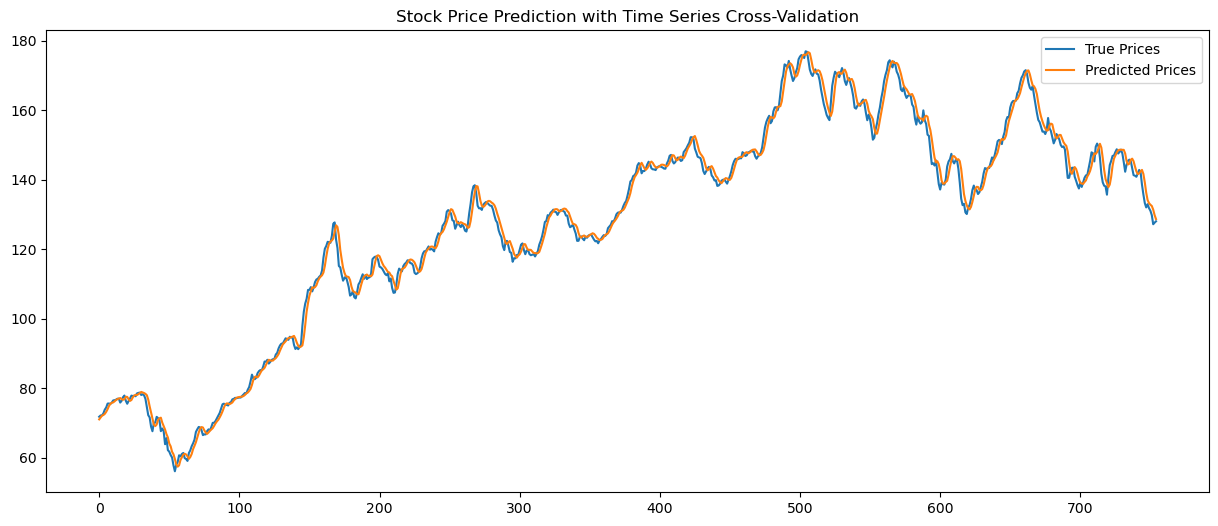

In [16]:
# Évaluation du modèle final
# Évaluer le modèle sur l'ensemble de test
test_loss, test_mae = final_model.evaluate(X_test, y_test)
print(f"Test Loss: {test_loss:.4f}, Test MAE: {test_mae:.4f}")

# Faire des prédictions
y_pred = final_model.predict(X_test)

# Convertir les prix prédits et réels à l'échelle initiale
y_test_unscaled = scaler.inverse_transform(y_test.reshape(-1, 1))
y_pred_unscaled = scaler.inverse_transform(y_pred)

# Tracer les résultats
plt.figure(figsize=(15, 6))
plt.plot(y_test_unscaled, label='True Prices')
plt.plot(y_pred_unscaled, label='Predicted Prices')
plt.title('Stock Price Prediction with Time Series Cross-Validation')
plt.legend()
plt.show()

In [17]:
# Métriques d'évaluation détaillées
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def calculate_directional_accuracy(y_true, y_pred):
    # Calcul des différences entre les points consécutifs
    y_true_direction = np.diff(y_true.flatten())
    y_pred_direction = np.diff(y_pred.flatten())
    
    # Calcul de la précision directionnelle
    correct_direction = np.sum((y_true_direction * y_pred_direction) > 0)
    return (correct_direction / len(y_true_direction)) * 100

# Calculer les métriques
mse = mean_squared_error(y_test_unscaled, y_pred_unscaled)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_unscaled, y_pred_unscaled)
r2 = r2_score(y_test_unscaled, y_pred_unscaled)
mape = calculate_mape(y_test_unscaled, y_pred_unscaled)
da = calculate_directional_accuracy(y_test_unscaled, y_pred_unscaled)

# Afficher les métriques
print("Métriques d'évaluation:")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R²: {r2:.4f}")
print(f"MAPE: {mape:.2f}%")
print(f"Directional Accuracy: {da:.2f}%")

Métriques d'évaluation:
MSE: 5.6206
RMSE: 2.3708
MAE: 1.8049
R²: 0.9939
MAPE: 1.45%
Directional Accuracy: 63.13%


In [18]:
#Sauvegarder le modèle final
final_model.save('../models/model_bilstm.keras')
print("Modèle sauvegardé avec succès!")

Modèle sauvegardé avec succès!
